# AI Cohort Beginner Project

## Description

This project has the objective of demonstrating the topics and skills learned from the AI Cohort Beginner Level courses. The problem selected for this project was the one presented by the [Telco Customer Churn](https://www.kaggle.com/datasets/blastchar/telco-customer-churn/data).

Churn: a regular, quantifiable process or rate of change that occurs in a business over a period of time as existing customers are lost and new customers are added

The objective is to predict behavior to retain customer, and thus lower the churn rate of the company by lunching retention campains against predicted churn customers. To achieve this, a binary classification model will be created to predict if a customer will leave the company services. Two models will be created: a neural network and a decision tree. Both models will be compared and a determination on which will fit best for the stated problem. Another objective is to try and explain why customers might decide to leave a company service given the dataset features.






## Explore and Clean Dataset

In [35]:
import pandas as pd
import numpy as np

In [36]:
pd.set_option('display.max_columns', None)
dataset = pd.read_csv('../data/Telco-Customer-Churn.csv')

In [37]:
dataset.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [38]:
dataset.describe(include='all')

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
count,7043,7043,7043.000000,7043,7043,7043.000000,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043,7043.000000,7043,7043
unique,7043,2,NaN,2,2,NaN,2,3,3,3,3,3,3,3,3,3,2,4,NaN,6531,2
top,7590-VHVEG,Male,NaN,No,No,NaN,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,NaN,20.2,No
freq,1,3555,NaN,3641,4933,NaN,6361,3390,3096,3498,3088,3095,3473,2810,2785,3875,4171,2365,NaN,11,5174
mean,NaN,NaN,0.162147,NaN,NaN,32.371149,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,64.761692,NaN,NaN
std,NaN,NaN,0.368612,NaN,NaN,24.559481,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,30.090047,NaN,NaN
min,NaN,NaN,0.000000,NaN,NaN,0.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,18.250000,NaN,NaN
25%,NaN,NaN,0.000000,NaN,NaN,9.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,35.500000,NaN,NaN
50%,NaN,NaN,0.000000,NaN,NaN,29.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,70.350000,NaN,NaN
75%,NaN,NaN,0.000000,NaN,NaN,55.000000,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,89.850000,NaN,NaN


In [39]:
#Verify if there are missing values
dataset.isna().sum()

customerID          0
gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

In [40]:
#Drop unique ID column
dataset = dataset.drop('customerID', axis=1)
dataset.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [41]:
#Verify the datatype of each column
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges            str
Churn                   str
dtype: object

In [42]:
#TotalCharges column value is of type str but represents a numerical value. Convert from str to float.
dataset['TotalCharges'] = pd.to_numeric(dataset['TotalCharges'], errors='coerce')
dataset.dtypes

gender                  str
SeniorCitizen         int64
Partner                 str
Dependents              str
tenure                int64
PhoneService            str
MultipleLines           str
InternetService         str
OnlineSecurity          str
OnlineBackup            str
DeviceProtection        str
TechSupport             str
StreamingTV             str
StreamingMovies         str
Contract                str
PaperlessBilling        str
PaymentMethod           str
MonthlyCharges      float64
TotalCharges        float64
Churn                   str
dtype: object

In [43]:
#blank strings were forced to convert to NaN.
dataset.isna().sum()

gender               0
SeniorCitizen        0
Partner              0
Dependents           0
tenure               0
PhoneService         0
MultipleLines        0
InternetService      0
OnlineSecurity       0
OnlineBackup         0
DeviceProtection     0
TechSupport          0
StreamingTV          0
StreamingMovies      0
Contract             0
PaperlessBilling     0
PaymentMethod        0
MonthlyCharges       0
TotalCharges        11
Churn                0
dtype: int64

In [44]:
#To address NaN values, will update NaN values to 0
#Explore examples with NaN values in TotalCahrges
dataset[dataset['TotalCharges'].isna()]

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
488,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,No,Yes,Yes,Yes,No,Two year,Yes,Bank transfer (automatic),52.55,NaN,No
753,Male,0,No,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.25,NaN,No
936,Female,0,Yes,Yes,0,Yes,No,DSL,Yes,Yes,Yes,No,Yes,Yes,Two year,No,Mailed check,80.85,NaN,No
1082,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.75,NaN,No
1340,Female,0,Yes,Yes,0,No,No phone service,DSL,Yes,Yes,Yes,Yes,Yes,No,Two year,No,Credit card (automatic),56.05,NaN,No
3331,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,19.85,NaN,No
3826,Male,0,Yes,Yes,0,Yes,Yes,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,25.35,NaN,No
4380,Female,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,Two year,No,Mailed check,20.00,NaN,No
5218,Male,0,Yes,Yes,0,Yes,No,No,No internet service,No internet service,No internet service,No internet service,No internet service,No internet service,One year,Yes,Mailed check,19.70,NaN,No
6670,Female,0,Yes,Yes,0,Yes,Yes,DSL,No,Yes,Yes,Yes,Yes,No,Two year,No,Mailed check,73.35,NaN,No


Since all examples with NaN in TotalCharges column have the value 0 in tenure, it means that the persons have not been charged yet since they have not completed a month receiving services from the service provider. We can convert NaN values to 0.

In [45]:
dataset['TotalCharges'] = dataset['TotalCharges'].fillna(0)
dataset.isna().sum()

gender              0
SeniorCitizen       0
Partner             0
Dependents          0
tenure              0
PhoneService        0
MultipleLines       0
InternetService     0
OnlineSecurity      0
OnlineBackup        0
DeviceProtection    0
TechSupport         0
StreamingTV         0
StreamingMovies     0
Contract            0
PaperlessBilling    0
PaymentMethod       0
MonthlyCharges      0
TotalCharges        0
Churn               0
dtype: int64

## Categorical Feature Analysis

/var/folders/_x/v31jblm52cq579qc0dzpptzm0000gn/T/ipykernel_74023/397236.py:6: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = dataset.select_dtypes(include='object').columns.tolist()


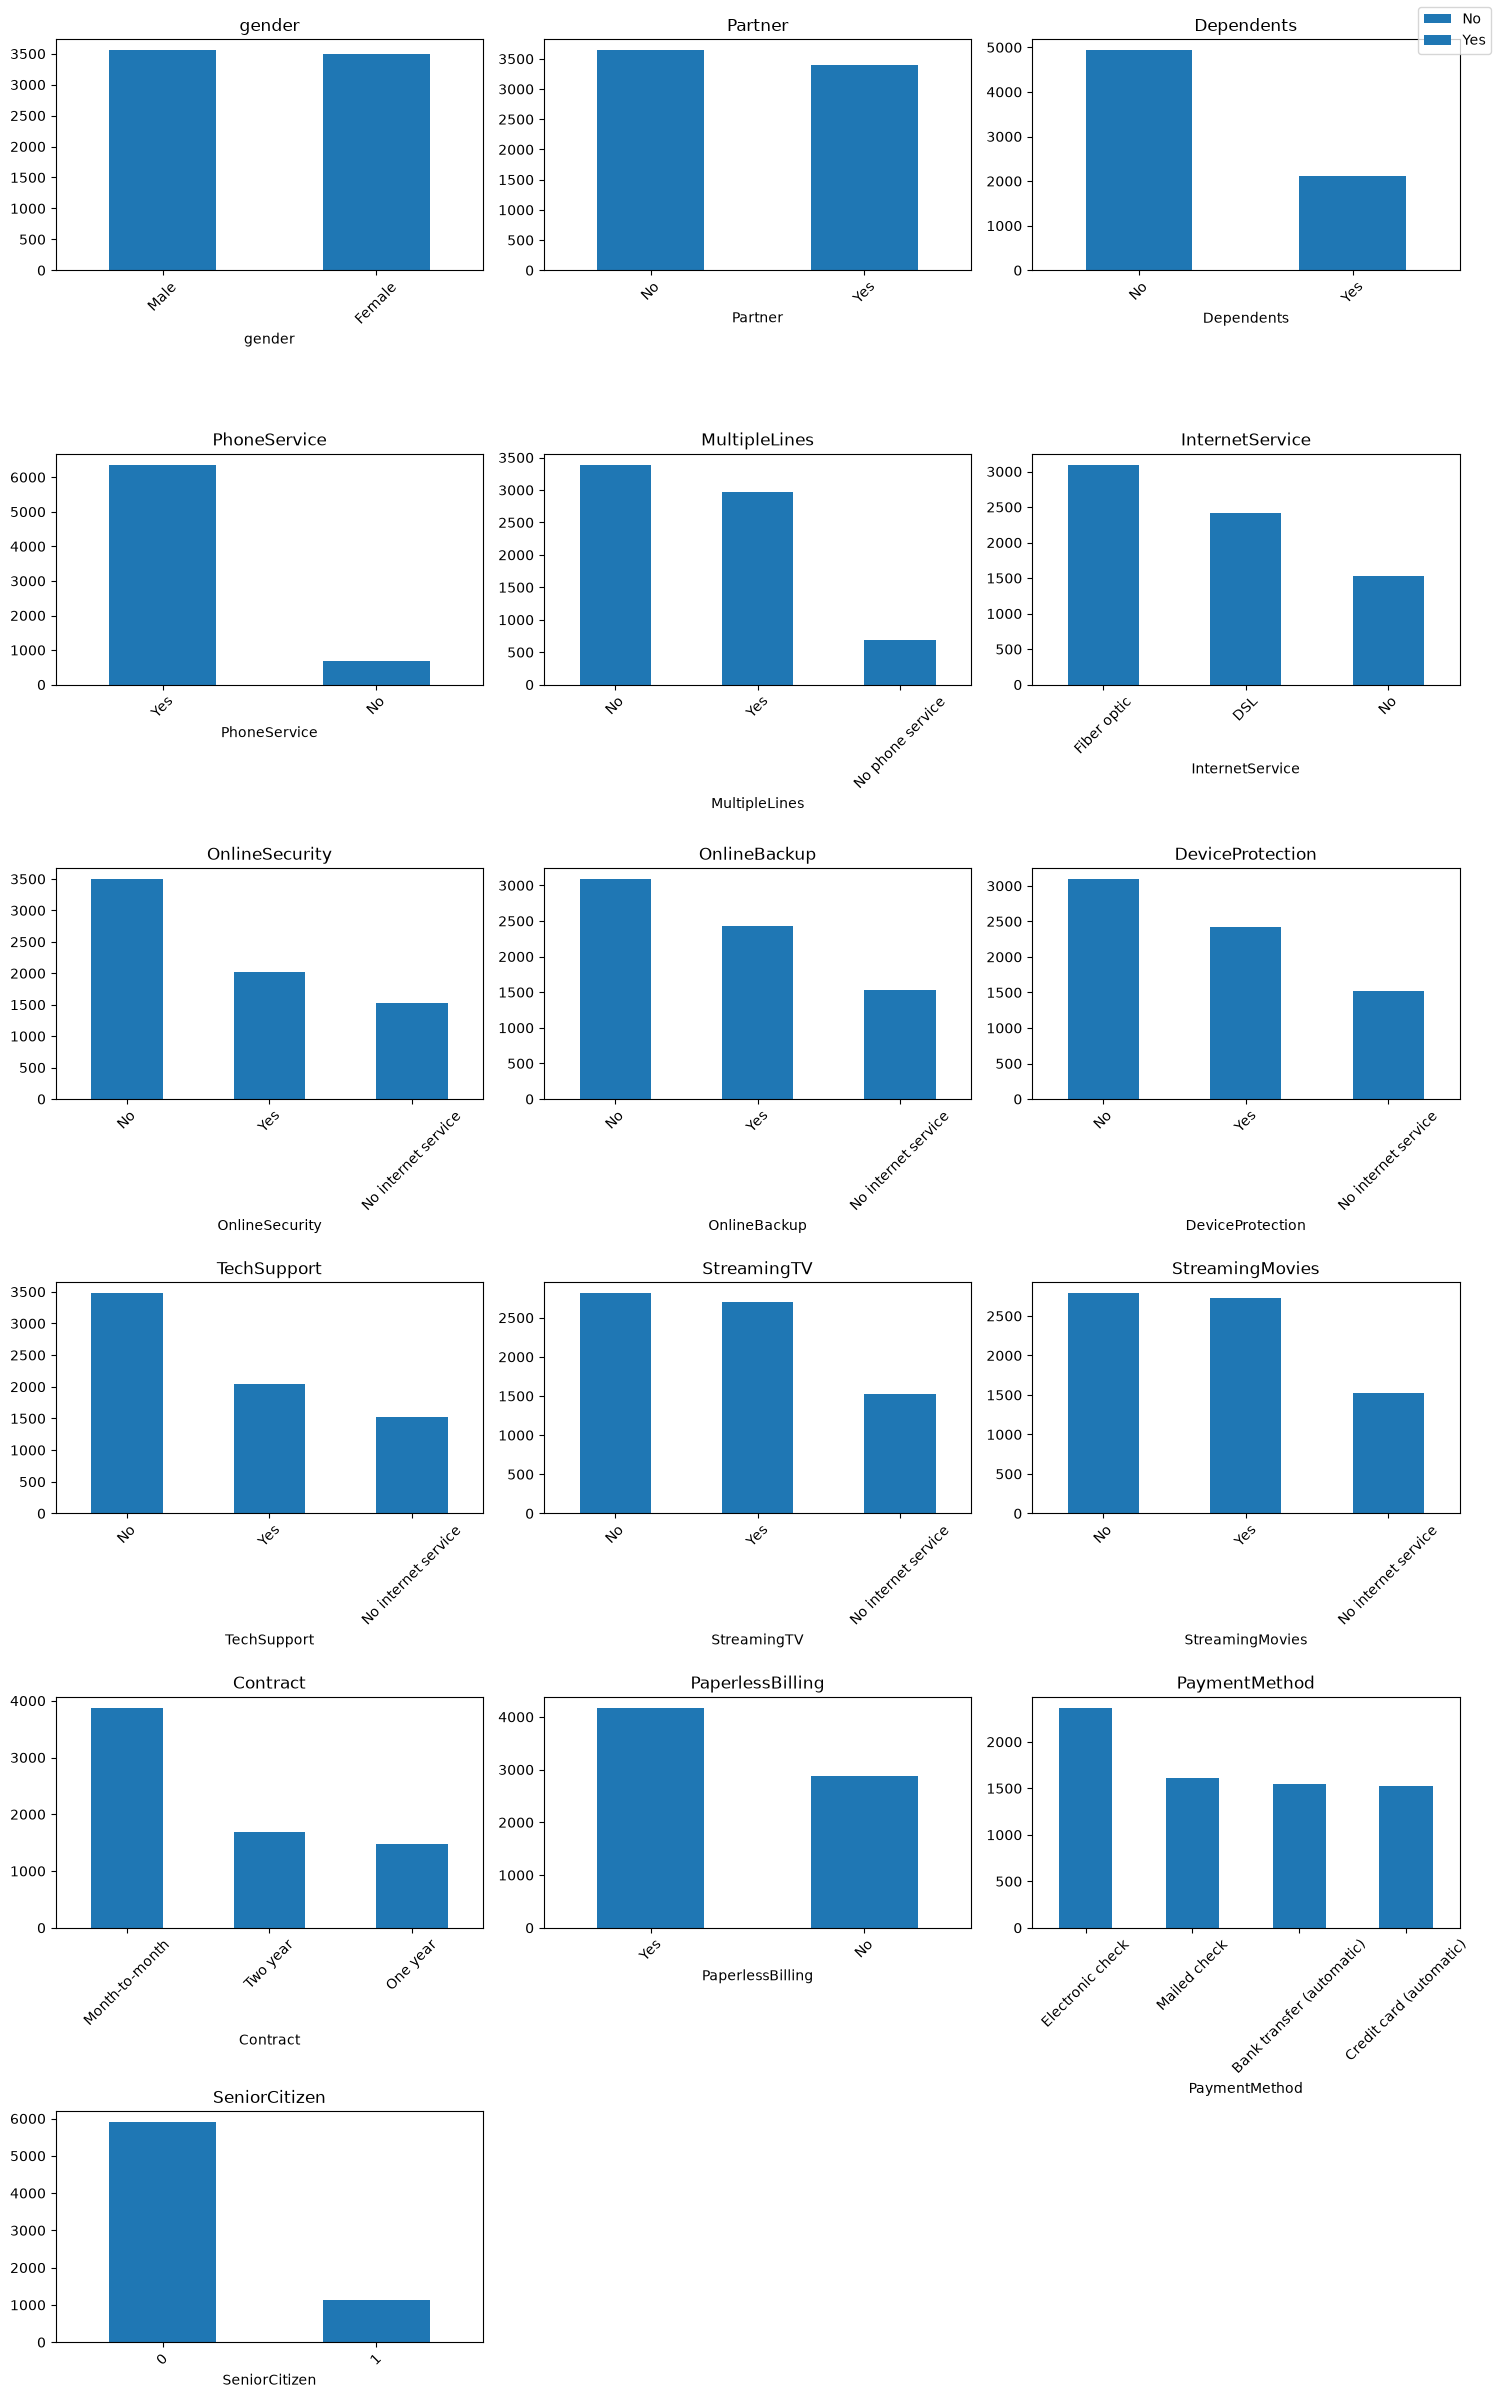

In [46]:
#Independent features analysis
import matplotlib.pyplot as plt
import seaborn as sns
import math

categorical = dataset.select_dtypes(include='object').columns.tolist()
categorical = [col for col in categorical if col != 'Churn']
categorical = categorical + ['SeniorCitizen']



numerical = dataset.select_dtypes(include="number").columns.tolist()
numerical = [col for col in numerical if col != 'SeniorCitizen']

def plot_categorical(data, cols, cols_per_row=3):
    rows = math.ceil(len(cols) / cols_per_row)
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5 * cols_per_row, 4 * rows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        data[col].value_counts().plot(kind="bar", stacked=True, ax=ax, legend=False)
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=45)

    for ax in axes[len(cols):]:
        ax.axis("off")

    fig.legend(["No", "Yes"], loc="upper right")
    plt.tight_layout()
    plt.show()

plot_categorical(dataset, categorical)

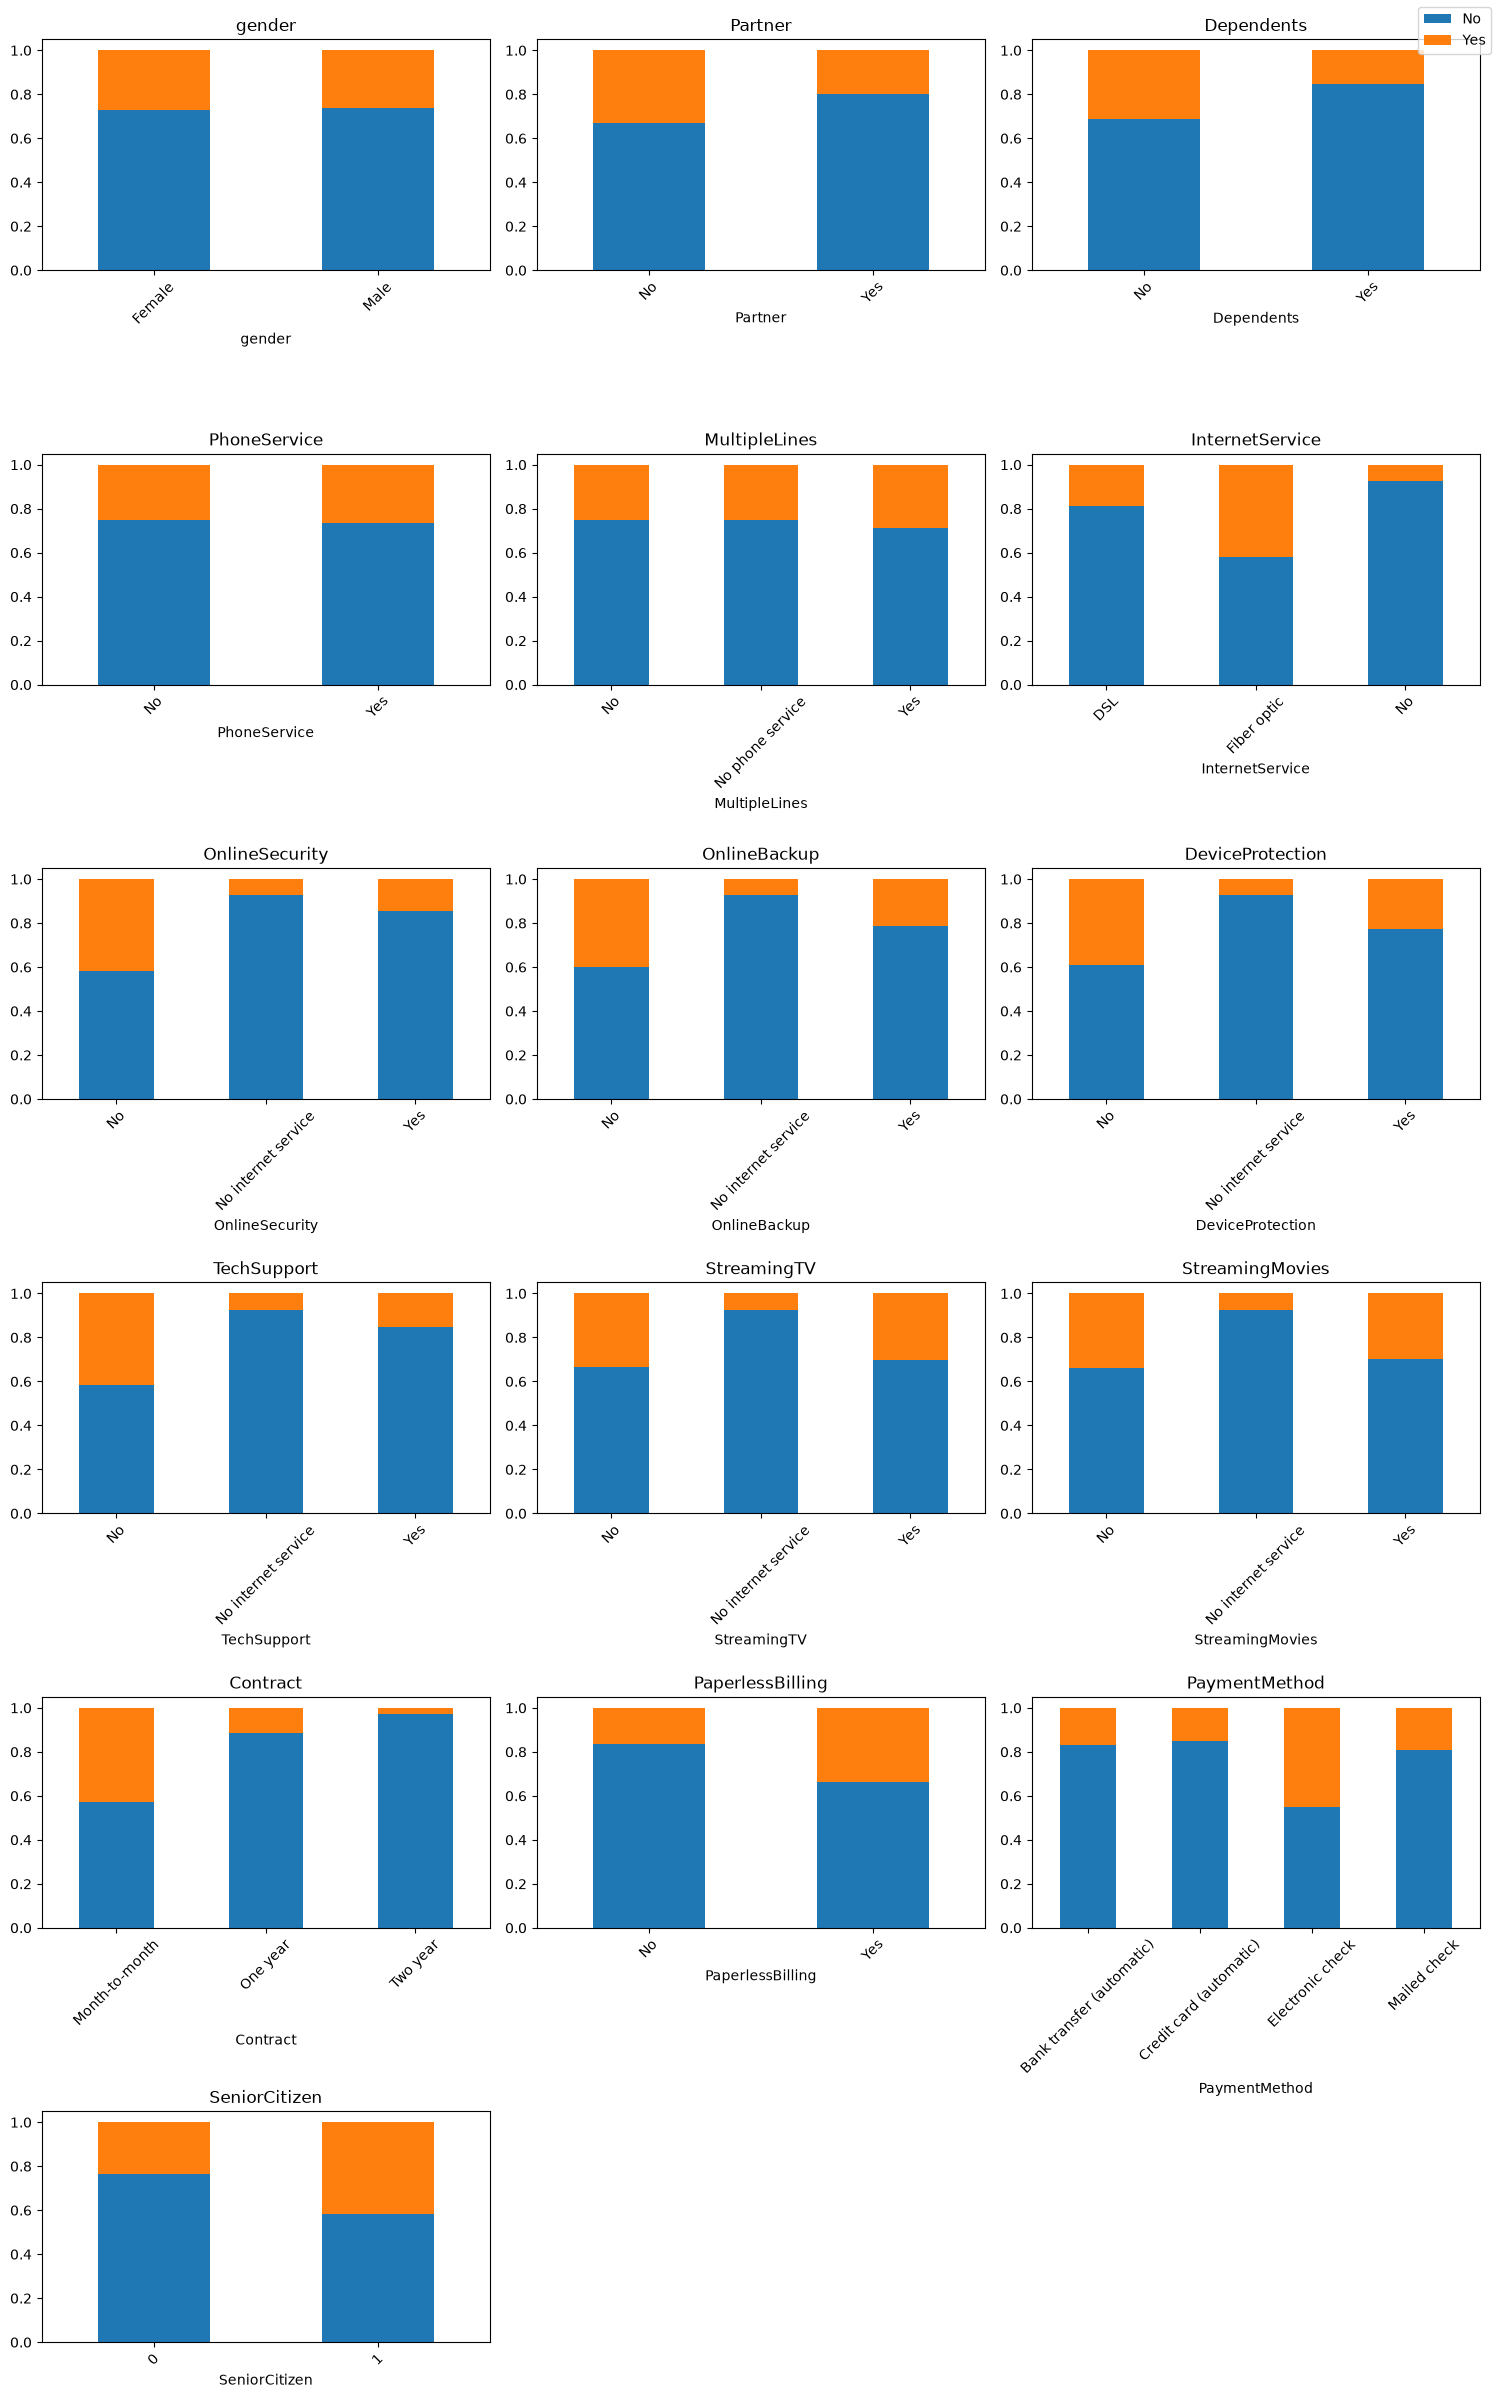

In [47]:
def plot_categorical_vs_churn(data, cols, target="Churn", cols_per_row=3):
    rows = math.ceil(len(cols) / cols_per_row)
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5 * cols_per_row, 4 * rows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        pd.crosstab(data[col], data[target], normalize="index").plot( #normalize="index"
            kind="bar", stacked=True, ax=ax, legend=False)
        ax.set_title(col)
        ax.tick_params(axis="x", rotation=45)

    for ax in axes[len(cols):]:
        ax.axis("off")

    fig.legend(["No", "Yes"], loc="upper right")
    plt.tight_layout()
    plt.show()

plot_categorical_vs_churn(dataset, categorical)




The following conclusions can be drawn from the categorical features analysis:
- The majority of contracts are month-to-month contracts and those with a month-to-month contract show a higher churn rate.
- Of those who have internet service, the majority has fiber optic internet, and those with fiber optic internet demonstrate higher churn rate.
- Those that do not have internet service show a lower churn rate than those with internet service.
- Those that do not have Online Security show a higher churn rate than those who do not. The same can be said about those who do not have Online Backup and Device Protection.
- Customers with electronic check as a payment method show a higher churn rate than those that use a different payment method.


## Numerical Features Analysis

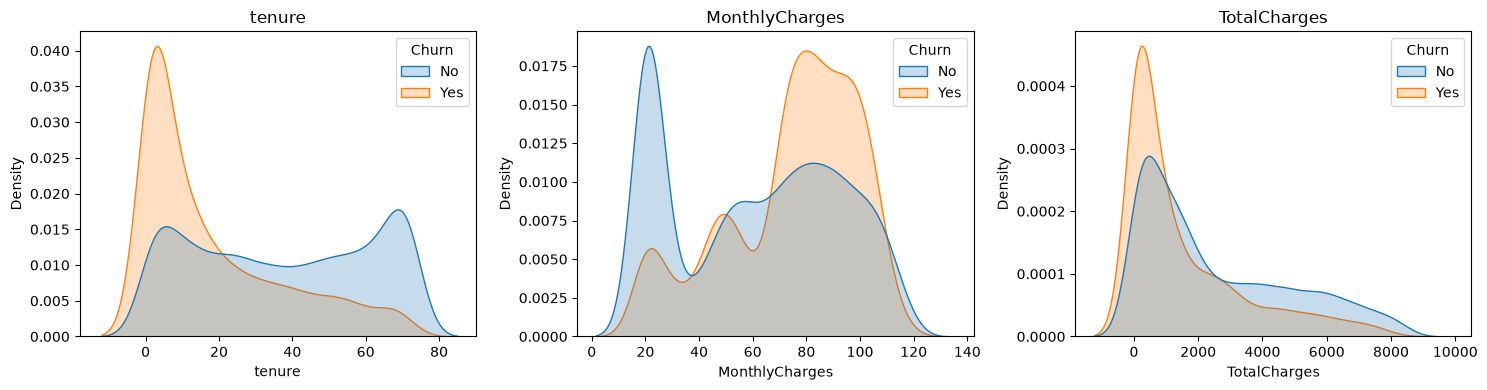

In [48]:
import seaborn as sns

def plot_numerical_vs_churn(data, cols, target="Churn", cols_per_row=3):
    rows = math.ceil(len(cols) / cols_per_row)
    fig, axes = plt.subplots(rows, cols_per_row, figsize=(5 * cols_per_row, 4 * rows))
    axes = axes.flatten()

    for ax, col in zip(axes, cols):
        sns.kdeplot(data=data, x=col, hue=target, common_norm=False, ax=ax, fill=True) #kernel density estimate
        ax.set_title(col)

    for ax in axes[len(cols):]:
        ax.axis("off")

    plt.tight_layout()
    plt.show()

plot_numerical_vs_churn(dataset, numerical)

Tenure, monthly charges and total charges are the only numerical features of the dataset. The above figures demonstrate the density of churn customers of each numerical feature. The following can be inferred:
- Customers with low tenure show a high churn rate than those with longer tenure.
- Churn rate increases as monthly charges increses.

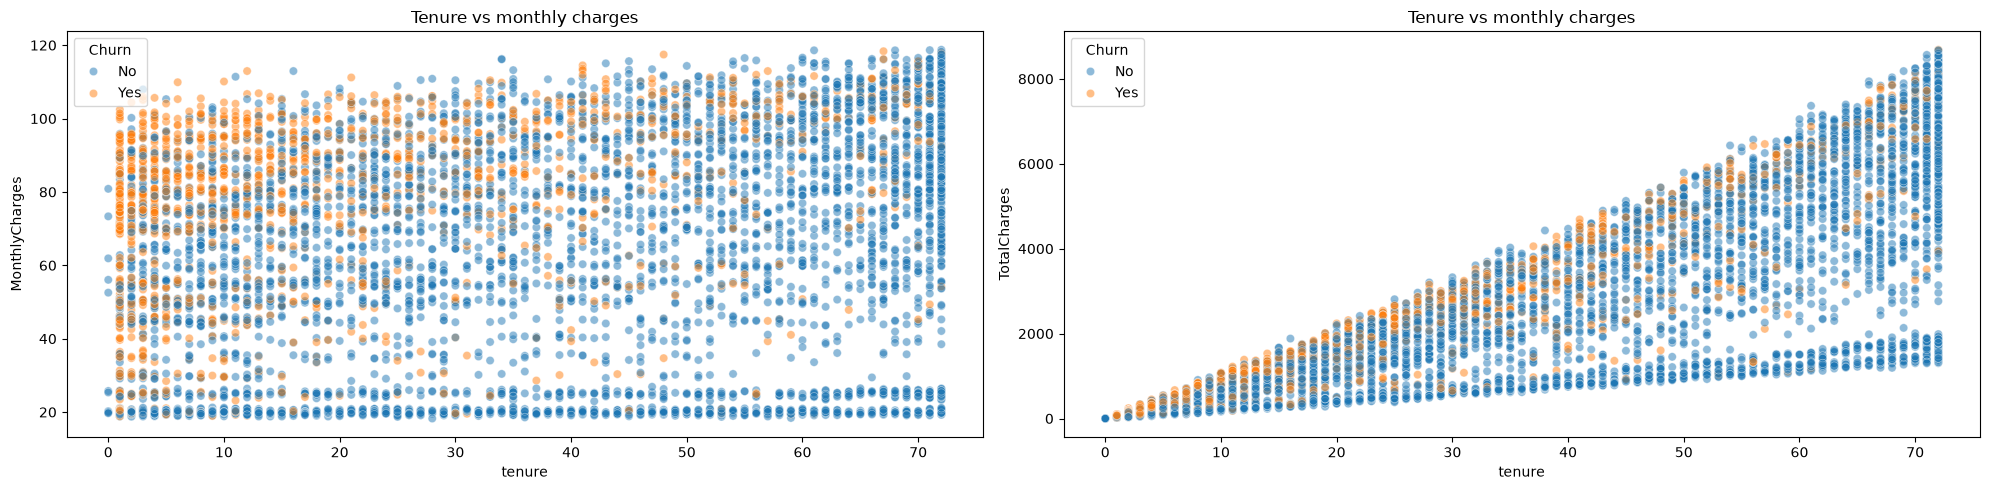

In [49]:
# Distribution of tenure and monthly charges, split by churn

fig, axes = plt.subplots(1, 2, figsize=(20,5))

# Scatter plot showing relation between tenure, monthly charges and churn
sns.scatterplot(data=dataset, x="tenure", y="MonthlyCharges", hue="Churn", alpha=0.5, ax=axes[0])
axes[0].set_title("Tenure vs monthly charges")

sns.scatterplot(data=dataset, x="tenure", y="TotalCharges", hue="Churn", alpha=0.5, ax=axes[1])
axes[1].set_title("Tenure vs monthly charges")

plt.tight_layout()
plt.show()

The first figure shows the relation between tenure, monthly charges and churn. It can be inferred that customers with lower tenure and higher monthly charges show a higher churn rate.
The scond figure shows the relation of tenure, total charges and churn. As expected, as tenure increases, total charges increases since total charges is the summation of monthly charges. It also shows that customers with higher total charges tend to leave the company services.

### Hot-on-encode categorical data

In [50]:
#Create a list of categorical data to give to get_dummies() pandas function.
#Encode binary features to 1 and 0
categorical_features = ['MultipleLines','InternetService','OnlineSecurity','OnlineBackup','DeviceProtection','TechSupport','StreamingTV','StreamingMovies','Contract','PaymentMethod']
binary_features = ['Partner','Dependents','PhoneService','PaperlessBilling','Churn']

for feature in binary_features:
    dataset[feature] = dataset[feature].map({'Yes': 1, 'No': 0})

dataset['gender'] = dataset['gender'].map({'Male': 1, 'Female': 0})

dataset.head(10)

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1
5,0,0,0,0,8,1,Yes,Fiber optic,No,No,Yes,No,Yes,Yes,Month-to-month,1,Electronic check,99.65,820.50,1
6,1,0,0,1,22,1,Yes,Fiber optic,No,Yes,No,No,Yes,No,Month-to-month,1,Credit card (automatic),89.10,1949.40,0
7,0,0,0,0,10,0,No phone service,DSL,Yes,No,No,No,No,No,Month-to-month,0,Mailed check,29.75,301.90,0
8,0,0,1,0,28,1,Yes,Fiber optic,No,No,Yes,Yes,Yes,Yes,Month-to-month,1,Electronic check,104.80,3046.05,1
9,1,0,0,1,62,1,No,DSL,Yes,Yes,No,No,No,No,One year,0,Bank transfer (automatic),56.15,3487.95,0


In [51]:
print(f'Dataset shape before one-hot-encoding categorical features: {dataset.shape}')

dataset = pd.get_dummies(dataset, columns=categorical_features, dtype=int)

print(f'Dataset shape after one-hot-encoding categorical features {dataset.shape}')

dataset.head(10)

Dataset shape before one-hot-encoding categorical features: (7043, 20)
Dataset shape after one-hot-encoding categorical features (7043, 41)


,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,PaperlessBilling,MonthlyCharges,TotalCharges,Churn,MultipleLines_No,MultipleLines_No phone service,MultipleLines_Yes,InternetService_DSL,InternetService_Fiber optic,InternetService_No,OnlineSecurity_No,OnlineSecurity_No internet service,OnlineSecurity_Yes,OnlineBackup_No,OnlineBackup_No internet service,OnlineBackup_Yes,DeviceProtection_No,DeviceProtection_No internet service,DeviceProtection_Yes,TechSupport_No,TechSupport_No internet service,TechSupport_Yes,StreamingTV_No,StreamingTV_No internet service,StreamingTV_Yes,StreamingMovies_No,StreamingMovies_No internet service,StreamingMovies_Yes,Contract_Month-to-month,Contract_One year,Contract_Two year,PaymentMethod_Bank transfer (automatic),PaymentMethod_Credit card (automatic),PaymentMethod_Electronic check,PaymentMethod_Mailed check
0,0,0,1,0,1,0,1,29.85,29.85,0,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
1,1,0,0,0,34,1,0,56.95,1889.50,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,0,1,0,0,0,0,1
2,1,0,0,0,2,1,1,53.85,108.15,1,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1
3,1,0,0,0,45,0,0,42.30,1840.75,0,0,1,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,0,1,0,1,0,0,0
4,0,0,0,0,2,1,1,70.70,151.65,1,1,0,0,0,1,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,1,0
5,0,0,0,0,8,1,1,99.65,820.50,1,0,0,1,0,1,0,1,0,0,1,0,0,0,0,1,1,0,0,0,0,1,0,0,1,1,0,0,0,0,1,0
6,1,0,0,1,22,1,1,89.10,1949.40,0,0,0,1,0,1,0,1,0,0,0,0,1,1,0,0,1,0,0,0,0,1,1,0,0,1,0,0,0,1,0,0
7,0,0,0,0,10,0,0,29.75,301.90,0,0,1,0,1,0,0,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,1,0,0,0,0,0,1
8,0,0,1,0,28,1,1,104.80,3046.05,1,0,0,1,0,1,0,1,0,0,1,0,0,0,0,1,0,0,1,0,0,1,0,0,1,1,0,0,0,0,1,0
9,1,0,0,1,62,1,0,56.15,3487.95,0,1,0,0,1,0,0,0,0,1,0,0,1,1,0,0,1,0,0,1,0,0,1,0,0,0,1,0,1,0,0,0


In [52]:
#Separate dataset into features and label. I will create two datasets for the project. One for a Neurla Network model and one for a decision tree model.
y_nn = dataset['Churn']
#y_dt = dataset['Churn']
X_nn = dataset.drop('Churn', axis=1)
#X_dt = dataset.drop('Churn', axis=1)

print(y_nn.shape)
#print(y_dt.shape)
print(X_nn.shape)
#print(X_dt.shape)

(7043,)
(7043, 40)


In [53]:
#For a classification dataset, verify how balanced is the target data. How many 1 and 0. 
#This can show if dataset is skewed and thus helps select which evaluation metric use (Accuracy, Recall, Recision, etc)
y_nn.value_counts().loc[[0, 1]]

Churn
0    5174
1    1869
Name: count, dtype: int64

The label data is skewed since approximately 74.5% of labels are No-Churn and 25.5% is Churn. 

## Neural Network Model

In [54]:
#We need to split the dataset intro training, validate and test sets. Sets will be split using a 60/20/20 rule.
from sklearn.model_selection import train_test_split

X_train_nn, X_, y_train_nn, y_ = train_test_split(X_nn, y_nn, test_size=0.4, random_state=3)

X_val_nn, X_test_nn, y_val_nn, y_test_nn = train_test_split(X_, y_, test_size=0.5, random_state=3)

print(f'Shape of training dataset: {X_train_nn.shape}')
print(f'Shape of validation dataset: {X_val_nn.shape}')
print(f'Shape of test dataset: {X_test_nn.shape}')
print(f'Shape of the training target values: {y_train_nn.shape}')
print(f'Shape of the validation target values: {y_val_nn.shape}')
print(f'Shape of the test target values: {y_test_nn.shape}')

Shape of training dataset: (4225, 40)
Shape of validation dataset: (1409, 40)
Shape of test dataset: (1409, 40)
Shape of the training target values: (4225,)
Shape of the validation target values: (1409,)
Shape of the test target values: (1409,)


In [55]:
#For a Neural Network, we want to make sure all features are in the same scale. We will use StandardScaler to scale the tenure, MonthlyCharges and TotalCharges
from sklearn.preprocessing import StandardScaler

columns_to_scale = ['tenure', 'MonthlyCharges', 'TotalCharges']

scaler_nn = StandardScaler()
X_train_nn_scaled = scaler_nn.fit_transform(X_train_nn, )
X_val_nn_scaled = scaler_nn.transform(X_val_nn)
X_test_nn_scaled = scaler_nn.transform(X_test_nn)

type(X_train_nn_scaled)
X_train_nn_scaled[:5,]

array([[-0.97868857, -0.43912289, -0.97360272, -0.65816034,  0.14117493,
         0.32471861,  0.83269849,  0.82019282,  0.4663063 , -0.95305338,
        -0.32471861,  1.15454113,  1.37544716, -0.88896245, -0.51989869,
        -1.00165818, -0.51989869,  1.57852321,  1.12544698, -0.51989869,
        -0.72741666, -0.89024316, -0.51989869,  1.37760851, -0.99410024,
        -0.51989869,  1.5640225 , -0.82578856, -0.51989869,  1.27253402,
        -0.80287533, -0.51989869,  1.23690748, -1.09987637,  1.94965032,
        -0.56851299, -0.52760412,  1.90196907, -0.71641618, -0.54114661],
       [-0.97868857, -0.43912289, -0.97360272, -0.65816034,  0.99892648,
        -3.07958942,  0.83269849, -0.79732739, -0.01530492, -0.95305338,
         3.07958942, -0.86614498,  1.37544716, -0.88896245, -0.51989869,
        -1.00165818, -0.51989869,  1.57852321,  1.12544698, -0.51989869,
        -0.72741666, -0.89024316, -0.51989869,  1.37760851, -0.99410024,
        -0.51989869,  1.5640225 ,  1.21096373, -0.

In [56]:
#Create model arquitecture
from tensorflow.keras.utils import set_random_seed
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dense, Input
from tensorflow.keras.optimizers import Adam
from tensorflow.keras.losses import BinaryCrossentropy

set_random_seed(42)


model1 = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu'),
    Dense(64, activation='relu'),
    Dense(32, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model1.compile(optimizer='adam', loss=BinaryCrossentropy())




In [57]:
#Train model 
history1 = model1.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=100, verbose=0
)

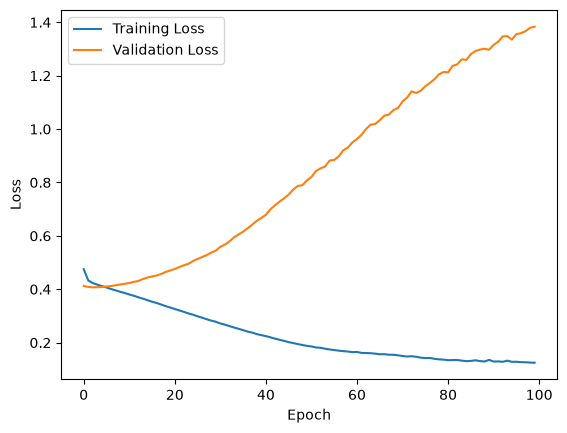

In [58]:
plt.plot(history1.history['loss'], label='Training Loss')
plt.plot(history1.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

The history shows that the training loss gets smaller, while the validation loss gets bigger. We can conclude that the model overfitts the training data. To address the high variance, a less complex model architecture can be designed, as well as include a regularization parameter. 

In [59]:
#Try a less complex neural netowrk. Can help for overfitting.

model2 = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu'),
    Dense(8, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model2.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history2 = model2.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=100, verbose=0
)




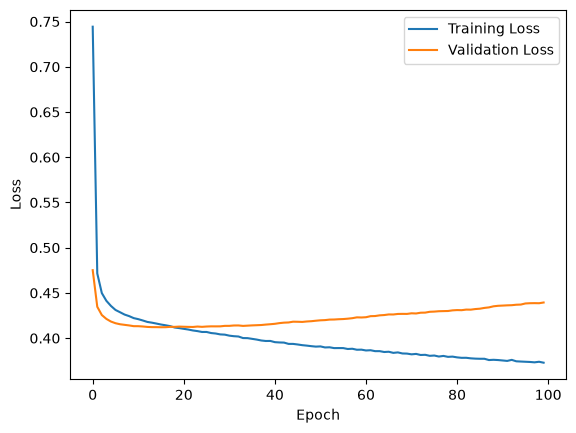

In [60]:
#Plot history for model2
plt.plot(history2.history['loss'], label='Training Loss')
plt.plot(history2.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [61]:
#After epoch 10, training loss and validation loss diverge greatly, still showing high variance problem. Lets try another model arquitecture.

model3 = Sequential([
    Input(shape=(X_train_nn_scaled.shape[1],)),
    Dense(8, activation='relu'),
    Dense(4, activation='relu'),
    Dense(1, activation='sigmoid')
    
])

model3.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history3 = model3.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50, verbose=0
)

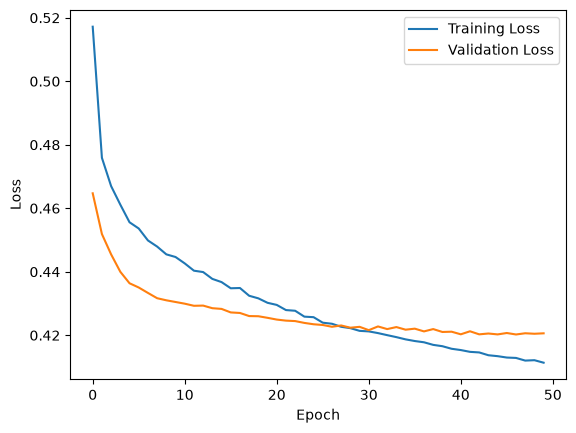

In [62]:
plt.plot(history3.history['loss'], label='Training Loss')
plt.plot(history3.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model 3 improves by lowering the variance and adapting better to new data.

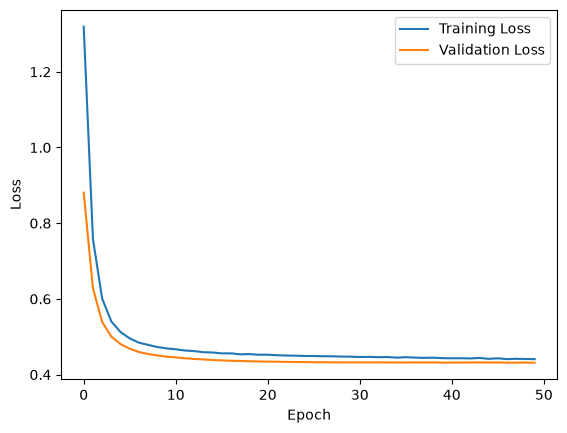

In [63]:
#Apply regularization for model1, model2 and model3
from tensorflow.keras.regularizers import l2

model1_r = Sequential([
    Input(shape=(40,)),
    Dense(40, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(64, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(32, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model1_r.compile(optimizer='adam', loss=BinaryCrossentropy())

history1_r =  model1_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50, verbose=0
)

plt.plot(history1_r.history['loss'], label='Training Loss')
plt.plot(history1_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()


Model1 seems to better fit new data when applying L2 regularization.


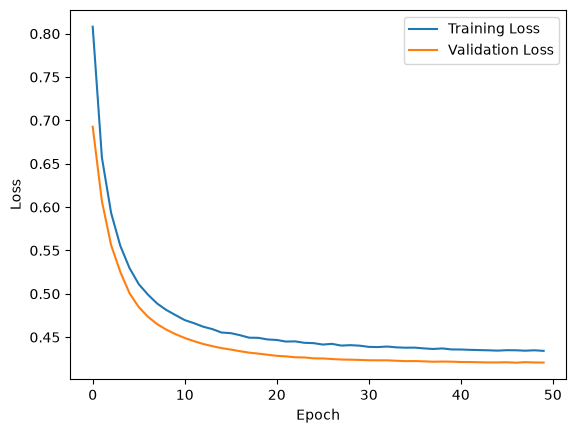

In [64]:
model2_r = Sequential([
    Input(shape=(40,)),
    Dense(16, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model2_r.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history2_r = model2_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50, verbose=0
)

plt.plot(history2_r.history['loss'], label='Training Loss')
plt.plot(history2_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

Model2 with regularization improves as well.

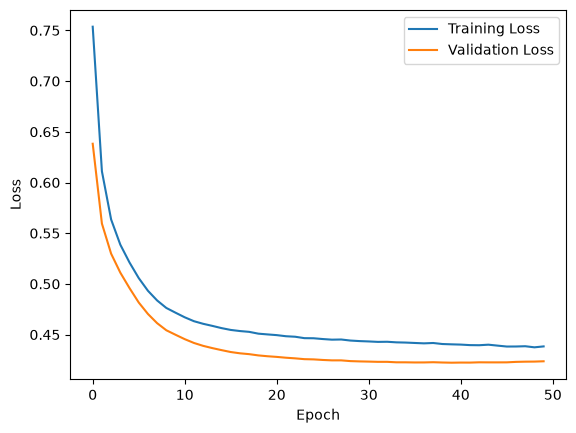

In [65]:
model3_r = Sequential([
    Input(shape=(X_train_nn_scaled.shape[1],)),
    Dense(8, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(4, activation='relu', kernel_regularizer=l2(0.01)),
    Dense(1, activation='sigmoid')
    
])

model3_r.compile(optimizer='adam', loss=BinaryCrossentropy())

#Train model 
history3_r = model3_r.fit(
    X_train_nn_scaled, y_train_nn, 
    validation_data=(X_val_nn_scaled, y_val_nn),
    epochs=50, verbose=0
)

plt.plot(history3_r.history['loss'], label='Training Loss')
plt.plot(history3_r.history['val_loss'], label='Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

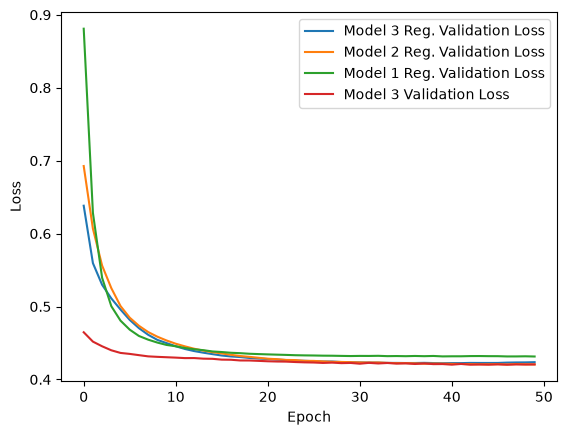

In [66]:
#Will select model3 without regularization as it gave the lower validation loss.
plt.plot(history3_r.history['val_loss'], label='Model 3 Reg. Validation Loss')
plt.plot(history2_r.history['val_loss'], label='Model 2 Reg. Validation Loss')
plt.plot(history1_r.history['val_loss'], label='Model 1 Reg. Validation Loss')
plt.plot(history3.history['val_loss'], label='Model 3 Validation Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

In [68]:
#Evaluate model on test data
from sklearn.metrics import classification_report, average_precision_score
loss = model3.evaluate(X_test_nn_scaled, y_test_nn, verbose=0)
print(f"model3: loss={loss:.4f}")

probabilities = model3.predict(X_test_nn_scaled)
#y_hat_nn = (probabilities >= 0.5).astype(int)
#y = y_test_nn.to_numpy().reshape(-1,1)
#print(classification_report(y, y_hat_nn))
print(average_precision_score(y_test_nn,probabilities)) #summarizes precision-recall curve


model3: loss=0.4369
45/45 ━━━━━━━━━━━━━━━━━━━━ 0s 427us/step
0.6436670684668624


Precision-Recall Area Under Curve: 0.2645
A 0.26 average precision score means...

              precision    recall  f1-score   support

           0       0.83      0.89      0.86      1018
           1       0.64      0.51      0.57       391

    accuracy                           0.78      1409
   macro avg       0.73      0.70      0.71      1409
weighted avg       0.77      0.78      0.78      1409



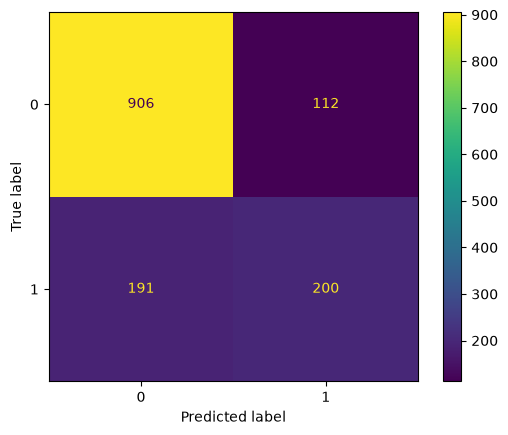

In [69]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay
y_hat_nn = (probabilities >= 0.5).astype(int)
y = y_test_nn.to_numpy().reshape(-1,1)
print(classification_report(y, y_hat_nn))

cm = confusion_matrix(y, y_hat_nn)
disp = ConfusionMatrixDisplay(cm)
disp.plot()

plt.show()
#true_positives = np.sum((y == 1) & (y_hat_nn == 1))
#actual_positives = np.sum(y == 1)

#recall = true_positives / actual_positives
#recall


The recall turns out to be 51.1%, which means that the model identified approximately half of customer churn. In other words, it failed to identify half of customer churns, which means that if the company were to use the trained model, it risks to overlook (not flag for retention outreach) half of customer churns. 

              precision    recall  f1-score   support

           0       0.85      0.83      0.84      1018
           1       0.59      0.63      0.61       391

    accuracy                           0.77      1409
   macro avg       0.72      0.73      0.72      1409
weighted avg       0.78      0.77      0.78      1409



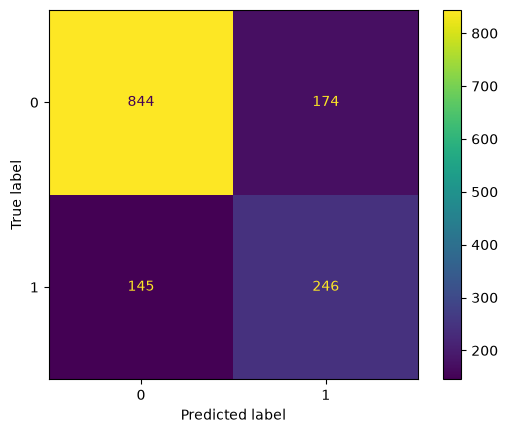

In [70]:
#Since we want to be able to identify more customer churns, we can lower the classification threshold. We gain more recall at the cost of lower precision.
y_hat_nn = (probabilities >= 0.4).astype(int)
print(classification_report(y, y_hat_nn))
#true_positives = np.sum((y == 1) & (y_hat_nn == 1))
#actual_positives = np.sum(y == 1)
#recall = true_positives / actual_positives
#print(recall)
cm = confusion_matrix(y, y_hat_nn)
disp = ConfusionMatrixDisplay(cm)
disp.plot()

plt.show()

              precision    recall  f1-score   support

           0       0.89      0.74      0.81      1018
           1       0.53      0.75      0.62       391

    accuracy                           0.74      1409
   macro avg       0.71      0.75      0.71      1409
weighted avg       0.79      0.74      0.75      1409



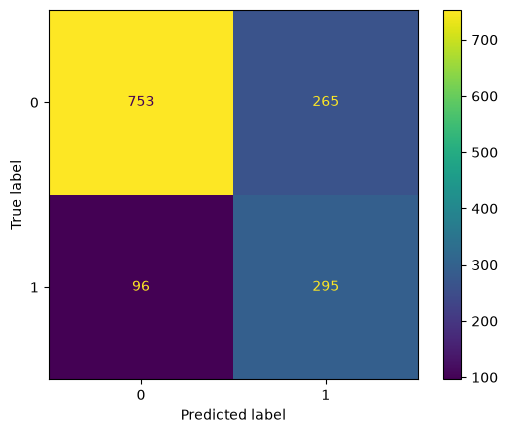

In [71]:
y_hat_nn = (probabilities >= 0.3).astype(int)
print(classification_report(y, y_hat_nn))

cm = confusion_matrix(y, y_hat_nn)
disp = ConfusionMatrixDisplay(cm)
disp.plot()

plt.show()


By lowering the threshold, the model achieves approximately a 75% of recall, which means it is able to classify 75% of churn customers at the expense of a lower precision. 

In [72]:
'''from sklearn.metrics import precision_recall_curve, average_precision_score
import matplotlib.pyplot as plt

# Use probabilities, not hard predictions
precision, recall, thresholds = precision_recall_curve(y, probabilities)

plt.figure(figsize=(7, 5))
plt.plot(recall, precision)
plt.xlabel('Recall')
plt.ylabel('Precision')
plt.title('Precision-Recall Curve')
plt.grid(True)
plt.show()
'''

"from sklearn.metrics import precision_recall_curve, average_precision_score\nimport matplotlib.pyplot as plt\n\n# Use probabilities, not hard predictions\nprecision, recall, thresholds = precision_recall_curve(y, probabilities)\n\nplt.figure(figsize=(7, 5))\nplt.plot(recall, precision)\nplt.xlabel('Recall')\nplt.ylabel('Precision')\nplt.title('Precision-Recall Curve')\nplt.grid(True)\nplt.show()\n"

Given that the dataset present a 25.5% of churn, by using the average precision score metric of 26.4%, this model is no better than guessing customer churn, since churners appear in the company population 

## Decision Tree Model

In [73]:
#X_train_dt
df = pd.read_csv('../data/Telco-Customer-Churn.csv')
X = df.drop(['Churn', 'customerID'], axis=1)
y = df['Churn'].map({'Yes': 1, 'No': 0})

X['TotalCharges'] = pd.to_numeric(X['TotalCharges'], errors='coerce')
X['TotalCharges'] = X['TotalCharges'].fillna(0)


X_train,X_, y_train, y_ = train_test_split(X,y, test_size=0.4, random_state=3, stratify=y)
X_val, X_test, y_val, y_test = train_test_split(X_,y_, test_size=0.5, random_state=3, stratify=y_)

print(X_train.shape)
print(X_val.shape)
print(X_test.shape)

print(y_train.shape)
print(y_val.shape)
print(y_test.shape)

(4225, 19)
(1409, 19)
(1409, 19)
(4225,)
(1409,)
(1409,)


In [74]:
#Need to pass to catboost a list of categorical features
categorical = X_train.select_dtypes(include='object').columns.tolist()
categorical

/var/folders/_x/v31jblm52cq579qc0dzpptzm0000gn/T/ipykernel_74023/1226728062.py:2: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = X_train.select_dtypes(include='object').columns.tolist()


['gender',
 'Partner',
 'Dependents',
 'PhoneService',
 'MultipleLines',
 'InternetService',
 'OnlineSecurity',
 'OnlineBackup',
 'DeviceProtection',
 'TechSupport',
 'StreamingTV',
 'StreamingMovies',
 'Contract',
 'PaperlessBilling',
 'PaymentMethod']

In [77]:
from catboost import CatBoostClassifier, Pool
from sklearn.metrics import (
    average_precision_score,
    classification_report,
    log_loss,
    precision_recall_curve,
    roc_auc_score,
)

train_pool = Pool(X_train, y_train, cat_features=categorical)
val_pool = Pool(X_val, y_val, cat_features=categorical)
test_pool = Pool(X_test, y_test, cat_features=categorical)

base_model = CatBoostClassifier(
    eval_metric='AUC',
    auto_class_weights='Balanced',
    early_stopping_rounds=50,
    random_seed=3,
    logging_level='Silent'
)

param_grid = {
    "depth": [4, 6, 8],
    "learning_rate": [0.01, 0.3, 0.5, 1],
    "l2_leaf_reg": [1, 3, 9],
}


grid_result_base_model = base_model.grid_search(
    param_grid,
    X=train_pool,
    cv=5,
    partition_random_seed=3,
    search_by_train_test_split=False,
    verbose=False
)

best_params = grid_result_base_model["params"]
print("Best params:", best_params)
 
cv_res = grid_result_base_model["cv_results"]
best_idx = int(np.argmax(cv_res["test-AUC-mean"]))
print(f"Best CV AUC: {cv_res['test-AUC-mean'][best_idx]:.4f} "
      f"(+/- {cv_res['test-AUC-std'][best_idx]:.4f})")
 


Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate this metric on train, add hints=skip_train~false to metric parameters.
Metric AUC is not calculated on train by default. To calculate

In [76]:
# Use best params for final catboost model.
final_params = {**best_params, "iterations": 2000}
final_model = CatBoostClassifier(
    **final_params,
    eval_metric="AUC",
    auto_class_weights="Balanced",
    early_stopping_rounds=100,
    random_seed=3,
    verbose=False,
)
final_model.fit(train_pool, eval_set=val_pool, use_best_model=True)
 
# Choose the probability cutoff on VALIDATION data (never on test).
val_proba = final_model.predict_proba(val_pool)[:, 1]
prec, rec, thr = precision_recall_curve(y_val, val_proba)
f1 = 2 * prec * rec / (prec + rec + 1e-12)
best_thr = thr[np.argmax(f1[:-1])]
print(f"\nThreshold chosen on validation (max F1): {best_thr:.3f}")
 
# ------------------------------------------------------------ 4. Evaluate on test
test_proba = final_model.predict_proba(test_pool)[:, 1]
test_pred = (test_proba >= best_thr).astype(int)
 
print(f"\nTest ROC AUC:           {roc_auc_score(y_test, test_proba):.4f}")
print(f"Test PR AUC (avg prec): {average_precision_score(y_test, test_proba):.4f}")
print(f"Test Logloss:           {log_loss(y_test, test_proba):.4f}\n")
print(classification_report(y_test, test_pred, target_names=["No churn", "Churn"]))


Threshold chosen on validation (max F1): 0.542

Test ROC AUC:           0.8400
Test PR AUC (avg prec): 0.6396
Test Logloss:           0.4966

              precision    recall  f1-score   support

    No churn       0.90      0.77      0.83      1035
       Churn       0.55      0.77      0.64       374

    accuracy                           0.77      1409
   macro avg       0.72      0.77      0.73      1409
weighted avg       0.81      0.77      0.78      1409



In [340]:
importances = final_model.get_feature_importance(prettified=True)
importances.head()

,Feature Id,Importances
0,Contract,32.399958
1,InternetService,18.523558
2,tenure,15.378901
3,TotalCharges,5.401361
4,PaymentMethod,5.111096


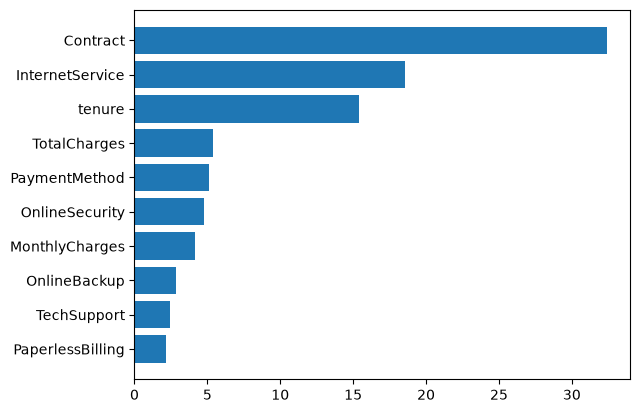

In [341]:
plt.barh(importances['Feature Id'][:10], importances['Importances'][:10])
plt.gca().invert_yaxis()
plt.show()

## Conclusion
